# 00 · The turtle's world

This series answers one question in several ways: **where is the turtle?**

A turtle wanders in a square arena. We command it (*"turn a little, walk 4 units"*),
but it never does exactly what it is told, and its sensors are noisy. Every notebook builds
a filter that combines the commands and the measurements into a *belief* about the turtle's
pose, and every filter runs on **the same simulated world and the same data**, so they can be
compared fairly.

| Notebook | Filter | Belief is represented by |
|---|---|---|
| 00 | — | (the world and its models) |
| 01 | Bayes filter, grid filter | a probability table |
| 02 | Kalman filter | a Gaussian, exact for linear models |
| 03 | Extended Kalman filter | a Gaussian, models linearised |
| 04 | Unscented Kalman filter | a Gaussian, propagated through sigma points |
| 05 | Particle filter | weighted samples |
| 06 | Showdown | all of them, on the same runs |

This notebook sets up the world: the state, the motion model, the sensors and the simulator
(`bayesian_filters/world.py`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))  # make `bayesian_filters` importable

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import World, simulate, motion_model, range_bearing, wrap_angle
from bayesian_filters import viz
viz.style()

## 1. State and control

The **state** (or *pose*) of the turtle at time $t$ is
$$x_t = (p^x_t,\; p^y_t,\; \theta_t)^\top,$$
its position in the plane and its heading, an angle that we always keep in $[-\pi, \pi)$.

The **control** is $u_t = (s_t, \delta_t)^\top$: first turn by $\delta_t$, then walk $s_t$
along the new heading. The noise-free motion model is therefore
$$
f(x, u) = \begin{pmatrix} p^x + s\cos(\theta + \delta) \\ p^y + s\sin(\theta + \delta) \\ \theta + \delta \end{pmatrix}.
$$
The real turtle executes a corrupted control,
$$
x_{t+1} = f\big(x_t,\; u_t + \varepsilon_t\big), \qquad \varepsilon_t \sim \mathcal N\!\big(0,\, M\big),\quad
M = \operatorname{diag}(\sigma_s^2, \sigma_\delta^2).
$$
Note *where* the noise enters: in the control, not added to the state. Turning noise is then
converted into position noise **across** the direction of travel, and step noise **along** it.
This makes the motion model non-linear in the noise as well as in the state.

Equivalently, the model defines a conditional density $p(x_{t+1} \mid x_t, u_t)$, the
**transition density**. Let us look at it: start 1000 turtles at the same pose, apply the same
25 commands, and see where they end up.

step noise sigma_s = 0.4,  turn noise sigma_delta = 0.03 rad


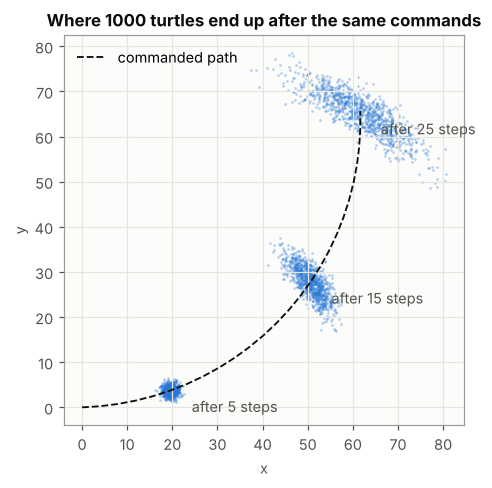

In [2]:
world = World.default()
print(f"step noise sigma_s = {world.sigma_step},  turn noise sigma_delta = {world.sigma_turn} rad")

rng = np.random.default_rng(0)
n, T = 1000, 25
x = np.zeros((n, 3))
u = np.array([4.0, np.pi / 50])
clouds = {}
for t in range(1, T + 1):
    x = motion_model(x, u + rng.normal(0, [world.sigma_step, world.sigma_turn], size=(n, 2)))
    if t in (5, 15, 25):
        clouds[t] = x.copy()
nominal = [np.zeros(3)]
for t in range(T):
    nominal.append(motion_model(nominal[-1], u))
nominal = np.array(nominal)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot(nominal[:, 0], nominal[:, 1], color=viz.INK, ls="--", lw=1.2, label="commanded path")
for t, c in clouds.items():
    ax.scatter(c[:, 0], c[:, 1], s=3, alpha=0.35, color=viz.COLORS["EKF"], lw=0)
    ax.annotate(f"after {t} steps", c[:, :2].mean(0), xytext=(14, -14), textcoords="offset points", color=viz.INK_2)
ax.set_aspect("equal"); ax.set_title("Where 1000 turtles end up after the same commands")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left")
plt.show()

The clouds are **not ellipses**: they bend into "bananas", because a heading error early on
is turned into a position error across the path, along an arc. A Gaussian belief (Kalman
filters, notebooks 02–04) can only approximate them; a grid (01) or particles (05) can
represent them exactly.

## 2. Sensors

The turtle carries three sensors. Different filters use different ones.

**Range–bearing to landmarks** (EKF, UKF, particle filter). For landmark $j$ at $\ell_j$,
$$
h_j(x) = \begin{pmatrix} \lVert \ell_j - p \rVert \\[2pt] \operatorname{atan2}(\ell^y_j - p^y,\; \ell^x_j - p^x) - \theta \end{pmatrix},
\qquad z_{t,j} = h_j(x_t) + \nu_{t,j}, \quad \nu_{t,j} \sim \mathcal N\!\big(0, \operatorname{diag}(\sigma_r^2, \sigma_\phi^2)\big).
$$
The bearing is measured *relative to the heading*, so it carries information about $\theta$.
Bearing differences must always be wrapped to $[-\pi,\pi)$: $\pi - 0.01$ and $-\pi + 0.01$ are
$0.02$ rad apart, not $2\pi - 0.02$.

The sensor may (or may not, see notebooks 05 and 06) report **which** landmark it saw;
this is the *data association* problem.

**GPS-like position fix** (linear KF): $z = p + \nu$, $\nu \sim \mathcal N(0, \sigma_{\text{gps}}^2 I)$.

**Compass** (linear KF and grid filter): $z = \theta + \nu$, $\nu \sim \mathcal N(0, \sigma_{c}^2)$.

In [3]:
for k in ["sigma_range", "sigma_bearing", "sigma_gps", "sigma_compass"]:
    print(f"{k:14s} = {getattr(world, k)}")

sigma_range    = 5.0
sigma_bearing  = 0.05
sigma_gps      = 8.0
sigma_compass  = 0.02


## 3. A simulated run

The commands follow a figure of eight (walk 4, turn $\pm\pi/50$, flip
the turning direction after each loop). The noise makes the turtle drift, so a "pilot" adds a
gentle extra turn towards the centre when it gets close to a wall. The pilot is part of the
*command*, which the filters know.

`simulate` returns a `Run` holding the true poses and everything the sensors reported.

truth: (401, 3)  controls: (400, 2)  range-bearing: (400, 4, 2)  gps: (400, 2)


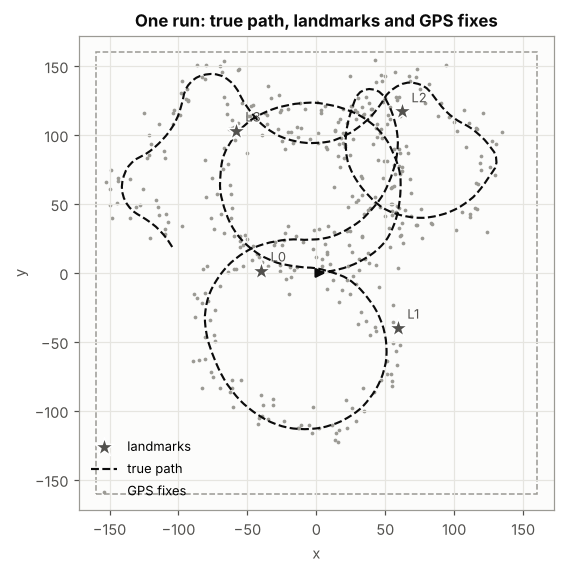

In [4]:
run = simulate(world, n_steps=400, seed=1)
print("truth:", run.truth.shape, " controls:", run.controls.shape,
      " range-bearing:", run.z_rb.shape, " gps:", run.z_gps.shape)

fig, ax = plt.subplots(figsize=(5.6, 5.6))
viz.plot_world(ax, world)
viz.plot_path(ax, run.truth, "truth", label="true path")
viz.plot_pose(ax, run.truth[0])
ax.scatter(run.z_gps[:, 0], run.z_gps[:, 1], s=6, color=viz.MUTED, lw=0, label="GPS fixes")
ax.set_title("One run: true path, landmarks and GPS fixes")
ax.legend(loc="lower left", fontsize=8.5)
plt.show()

The range–bearing measurements over time. Ranges are smooth; bearings jump by $2\pi$
whenever they cross $\pm\pi$, which is exactly why every filter must handle angles with care.

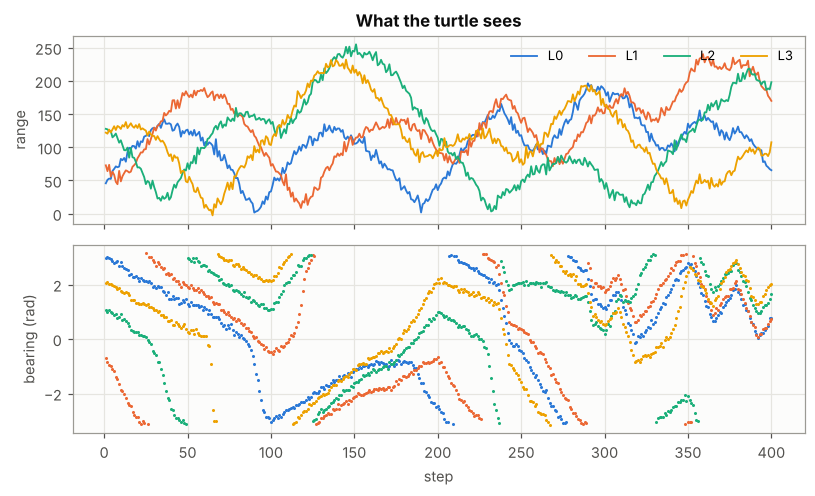

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(7.5, 4.6), sharex=True)
steps = np.arange(1, run.n_steps + 1)
for j in range(world.n_landmarks):
    c = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"][j]  # one colour per landmark
    axes[0].plot(steps, run.z_rb[:, j, 0], lw=1.2, color=c, label=f"L{j}")
    axes[1].plot(steps, run.z_rb[:, j, 1], ".", ms=2, color=c)
axes[0].set_ylabel("range"); axes[1].set_ylabel("bearing (rad)"); axes[1].set_xlabel("step")
axes[0].legend(ncol=4, loc="upper right", fontsize=8.5)
axes[0].set_title("What the turtle sees")
plt.tight_layout(); plt.show()

## 4. Why filter? Dead reckoning drifts

Ignoring the sensors and simply integrating the commands, $\hat x_{t+1} = f(\hat x_t, u_t)$,
is called **dead reckoning**. Its error is a random walk: the variance of the heading error
grows linearly in $t$, and the position error grows even faster because heading errors are
integrated along the path.

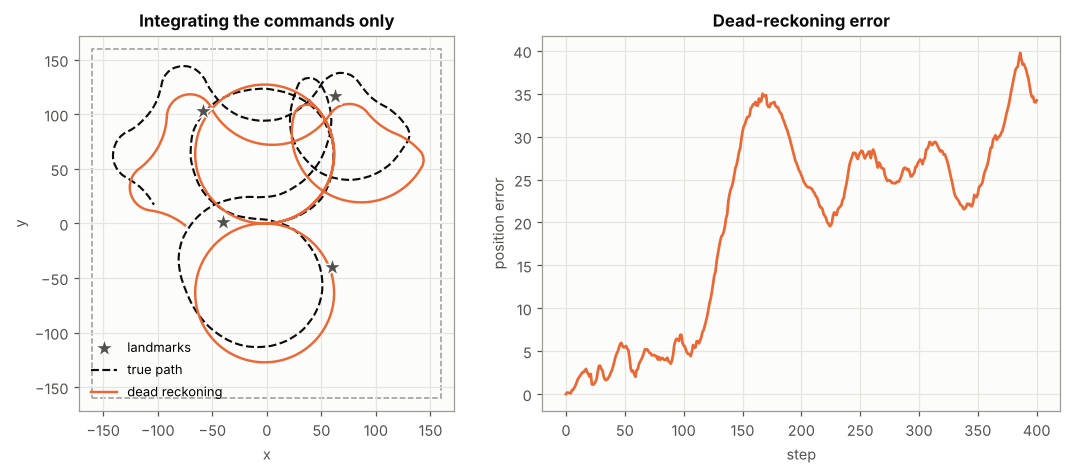

error after 100 steps: 5.6,  after 400 steps: 34.2


In [6]:
dr = [run.truth[0]]
for u_t in run.controls:
    dr.append(motion_model(dr[-1], u_t))
dr = np.array(dr)
err = np.hypot(*(dr[:, :2] - run.truth[:, :2]).T)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw=dict(width_ratios=[1, 1.25]))
viz.plot_world(a1, world, label_landmarks=False)
viz.plot_path(a1, run.truth, "truth", label="true path")
a1.plot(dr[:, 0], dr[:, 1], color=viz.COLORS["UKF"], lw=1.6, label="dead reckoning")
a1.legend(loc="lower left", fontsize=8.5); a1.set_title("Integrating the commands only")
a2.plot(err, color=viz.COLORS["UKF"], lw=1.8)
a2.set_xlabel("step"); a2.set_ylabel("position error"); a2.set_title("Dead-reckoning error")
plt.tight_layout(); plt.show()
print(f"error after 100 steps: {err[100]:.1f},  after 400 steps: {err[400]:.1f}")

Dead reckoning uses only the transition model; a lone GPS fix uses only the sensor model (with an RMS
error of $\sigma_{\text{gps}}\sqrt 2 \approx 11$ units, every single time). A **filter** uses both,
recursively. That is the subject of the next notebook.

## Summary: the state-space model

$$
\boxed{\;
\begin{aligned}
x_{t+1} &\sim p(x_{t+1} \mid x_t, u_t) &&\text{(motion: } f \text{ with noisy control)}\\
z_t &\sim p(z_t \mid x_t) &&\text{(sensor: } h \text{ plus noise)}
\end{aligned}\;}
$$

The state is **Markov**: given $x_t$, the future does not depend on the past, and $z_t$
depends only on $x_t$. Every filter in this series relies on those two assumptions.